# 03 — Linear SVM Main Model

**Owner:** Member 4  
**Goal:** select C using training-only cross-validation, lock the model, and produce traceable handoff artifacts.

## Experimental safeguards

- Reuse the fixed 796/200 split produced by Member 2.
- Reuse Member 3's selected unigram TF-IDF representation.
- Refit TF-IDF inside every validation fold through one pipeline.
- Select only C; do not revisit the n-gram choice.
- Evaluate the test set only after C is locked.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / 'src'))

from restaurant_sentiment.config import PROJECT_ROOT
from restaurant_sentiment.svm_experiment import run_svm_experiment

PROJECT_ROOT = Path(PROJECT_ROOT)
PROJECT_ROOT

PosixPath('/Users/zouxiangyu/Desktop/HKU/SEM1/8017/restaurant-sentiment')

## Run the reproducible experiment

This performs five-fold stratified selection on the training set, refits the winning pipeline, and then evaluates the untouched test partition once.

In [2]:
metadata = run_svm_experiment(PROJECT_ROOT, cv_folds=5)
print(json.dumps(metadata, indent=2))

{
  "random_state": 8017,
  "cv_folds": 5,
  "cv_splitter": "StratifiedKFold(shuffle=True, random_state=8017)",
  "selection_metric": "positive-class F1",
  "svm_c_grid": [
    0.1,
    1.0,
    10.0
  ],
  "selected_c": 0.1,
  "selected_cv_f1": 0.8059709477361103,
  "ngram_range": [
    1,
    1
  ],
  "train_rows": 796,
  "test_rows": 200,
  "test_set_used_only_after_c_locked": true,
  "test_metrics": {
    "accuracy": 0.74,
    "precision": 0.7790697674418605,
    "recall": 0.67,
    "f1": 0.7204301075268817,
    "roc_auc": 0.8061
  },
  "elapsed_seconds": 2.7107068330515176,
  "input_sha256": {
    "train.csv": "cb874f345b78bd41ed234354aafd84583fac5d96e39c0d2515e5b3adf2514e6c",
    "test.csv": "0e2af7309739fed02bd18dfb7e9a7f0edbc81f6e0e538efeeaf1093992b924cf",
    "split_manifest.csv": "78cfba981e05f17b9ac7504353acb404aceee0b3218301026fb9a681ef38cf2a"
  },
  "versions": {
    "python": "3.11.9",
    "numpy": "2.4.6",
    "pandas": "2.3.3",
    "scipy": "1.17.1",
    "scikit_learn":

## Training-only C comparison

,C,rank_f1,fit_time_mean_seconds,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,0.1,1,0.0245,0.8104,0.0369,0.8224,0.0252,0.7922,0.0670,0.8060,0.0441,0.8850,0.0279
1,1.0,3,0.0163,0.8015,0.0265,0.8054,0.0382,0.7996,0.0349,0.8016,0.0252,0.8953,0.0244
2,10.0,2,0.0145,0.8015,0.0242,0.8051,0.0441,0.8021,0.0345,0.8022,0.0212,0.8915,0.0307


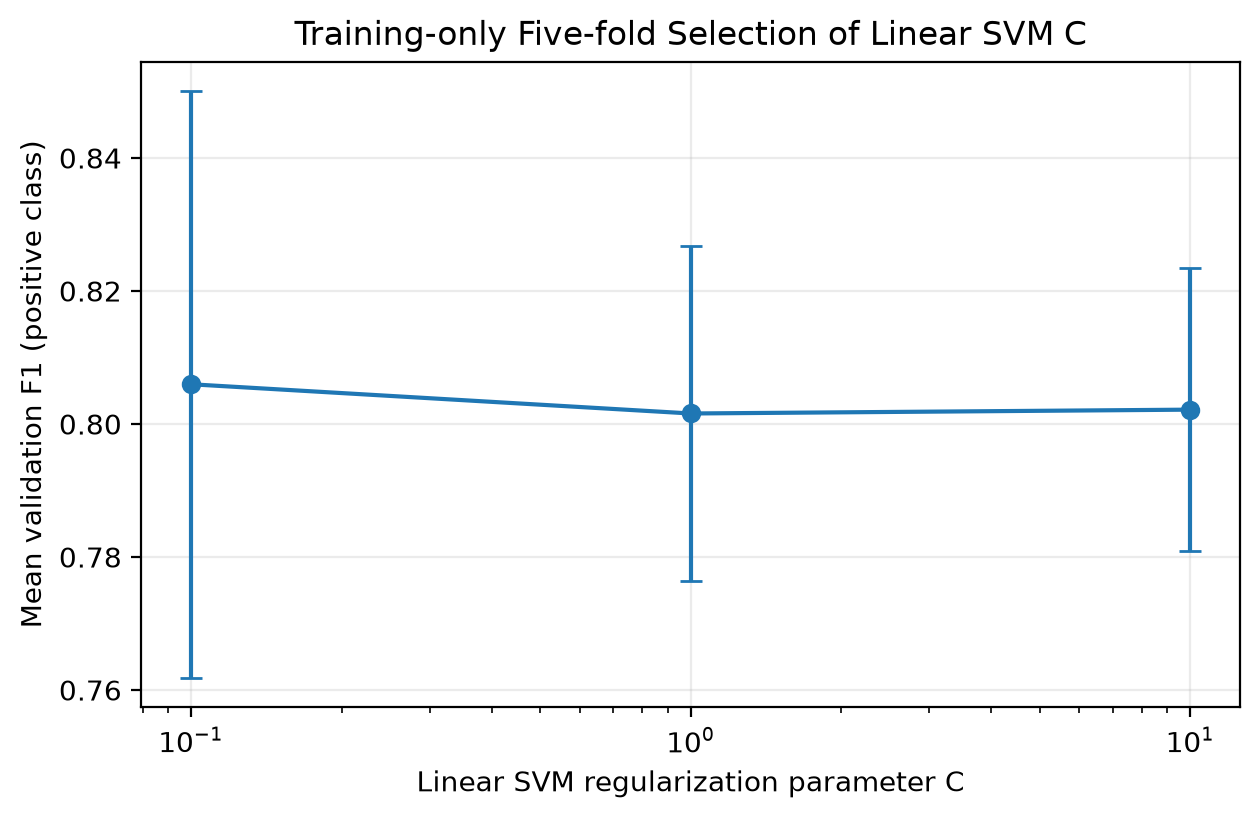

In [3]:
cv_results = pd.read_csv(PROJECT_ROOT / 'results/tables/svm_cv_results.csv')
display(cv_results.round(4))
display(Image(filename=PROJECT_ROOT / 'results/figures/svm_c_cv_f1.png'))

C=0.1 is selected because it has the highest mean positive-class validation F1. The settings are close, so this is a limited sensitivity analysis rather than evidence that one value is universally optimal.

## Locked test evaluation and interpretation

,model,accuracy,precision,recall,f1,roc_auc
0,svm,0.74,0.7791,0.67,0.7204,0.8061


,negative_term,negative_weight,positive_term,positive_weight
0,not,-1.3628,great,1.2942
1,at,-0.5960,good,1.0054
2,wasn,-0.5851,delicious,0.7861
3,don,-0.5783,fantastic,0.6527
4,bad,-0.5415,amazing,0.6254
5,no,-0.5002,nice,0.5368
6,terrible,-0.4963,friendly,0.5310
7,worst,-0.4940,awesome,0.5245
8,slow,-0.4737,you,0.5072
9,never,-0.4706,is,0.4751


,review_id,true_label,predicted_label,decision_score,correct
0,31,1,0,-0.174423,False
1,456,0,1,0.039055,False
2,38,0,0,-0.128317,True
3,377,0,0,-0.561793,True
4,367,0,0,-0.127449,True


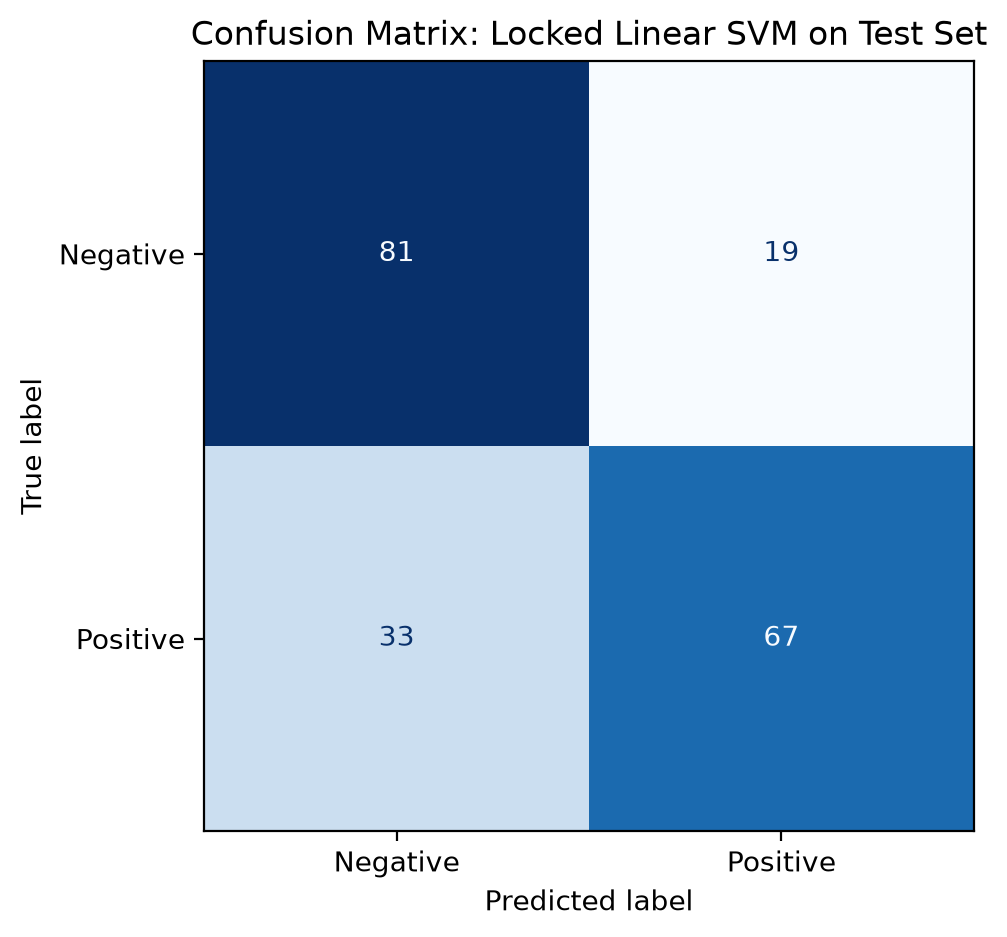

In [4]:
test_metrics = pd.read_csv(PROJECT_ROOT / 'results/tables/svm_test_metrics.csv')
top_terms = pd.read_csv(PROJECT_ROOT / 'results/tables/svm_top_terms.csv')
predictions = pd.read_csv(PROJECT_ROOT / 'results/tables/svm_test_predictions.csv')
display(test_metrics.round(4))
display(top_terms.head(10).round(4))
display(predictions.head())
display(Image(filename=PROJECT_ROOT / 'results/figures/svm_test_confusion_matrix.png'))

The locked model achieves test accuracy 0.7400, F1 0.7204, and ROC-AUC 0.8061. Precision (0.7791) exceeds recall (0.6700), suggesting conservative positive predictions. Coefficients identify corpus associations, not causal effects; Member 5 should use svm_c=0.1 in the unified evaluation.